# J2 El Mantaro — pronóstico de heladas (1–6 h) usando la humedad de hoja

**Estación**: solo **J2 El Mantaro** (3.314 m). Es la estación con mejor calidad de datos de hoja: 93 % de cobertura, línea base estable y 245 heladas blancas.

**¿Por qué la humedad de hoja podría ayudar en El Mantaro?**

1. Allí las heladas son mayoritariamente **blancas**, y el sensor (probablemente dieléctrico) **sí detecta la escarcha**.
2. El sensor **arriba** mira al cielo y el **bajo** mira al suelo. Con cielo despejado la cara superior pierde calor por radiación y se moja antes y más que la inferior. Por eso la diferencia **arriba − bajo** puede servir como **indicador de cielo despejado**, que es justo la información de nubosidad nocturna que le faltaba al modelo anterior.
3. El inicio del mojado indica que la superficie alcanzó el punto de rocío. A partir de ahí la condensación libera calor latente y el enfriamiento se frena: el punto de rocío actúa como "piso" de la temperatura.
4. El sensor mide **en la superficie**, que está más fría que el aire a 2 m. Se adelanta a la temperatura del abrigo meteorológico.

**Diseño**

* Variables de hoja **construidas** a partir de la señal cruda: valor relativo a la línea base seca (calculada solo con datos pasados, lo que además corrige la deriva), horas mojado en la noche, tendencias y diferencia arriba − bajo.
* Dos umbrales de helada: **meteorológica** (`Tmin ≤ 0 °C`) y **agronómica** (`Tmin ≤ 2 °C`).
* Tres variantes de modelo: **sin hoja**, **hoja cruda** (como en el notebook anterior) y **hoja construida**.
* **Validación cruzada dejando un año fuera** (2022…2026). Cada temporada de heladas (abril–octubre) cae entera dentro de un año, así que no se mezclan noches entre entrenamiento y prueba. Así aprovechamos todas las heladas para evaluar, que en una sola estación son pocas.
* **Bootstrap por noche** para saber si las diferencias entre variantes son reales o ruido.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, mean_absolute_error
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
OUT = BASE / 'resultados'; (OUT / 'modelos').mkdir(parents=True, exist_ok=True)

ESTACIONES = ['j2_el_mantaro']
RECORTE = {}
UMBRALES = {'meteorologica': 0.0, 'agronomica': 2.0}
LEADS = list(range(1, 7))
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))
UMB_MOJADO = 10      # % por encima de la línea base seca para considerar la hoja "mojada"
P_ALERTA = 0.5       # umbral de probabilidad fijo para emitir alerta (igual para todas las variantes)
N_BOOT = 1000
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Datos y variables

In [2]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
meta['etiqueta'] = (meta['codigo'].fillna('') + ' ' + meta['nombre']).str.strip()
ETQ = meta['etiqueta'].to_dict()

REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'arriba',
       'rh_hoja_bajo_media_1h': 'bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def cargar(est):
    f = DATA / 'horario' / f'{est}.csv'
    cols = [c for c in ['fecha', *REN] if c in pd.read_csv(f, nrows=0).columns]
    d = pd.read_csv(f, usecols=cols, parse_dates=['fecha']).set_index('fecha').rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    d = d.asfreq('h')
    if est in RECORTE: d = d.loc[:RECORTE[est]]
    return d

def var_meteo(d, est):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()
    rad24 = d['rad'].rolling(24, min_periods=18).sum()
    X['claridad_24h'] = rad24 / rad24.rolling('60D', min_periods=24 * 20).quantile(.95)   # solo pasado
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    X['altitud'] = meta.loc[est, 'altitud_m']
    return X

def var_hoja(d):
    X = pd.DataFrame(index=d.index)
    seco = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    noche = (d.index - pd.Timedelta(hours=12)).normalize()
    for k in ('arriba', 'bajo'):
        # línea base seca: mediana de las horas secas de los 30 días previos (solo pasado -> corrige deriva)
        base = d[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
        rel = d[k] - base
        X[f'{k}_base'] = base
        X[f'{k}_rel'] = rel
        for L in (1, 3):
            X[f'{k}_d{L}h'] = rel - rel.shift(L)
        X[f'{k}_max3h'] = rel.rolling(3, min_periods=2).max()
        mojado = (rel > UMB_MOJADO).astype(float).where(rel.notna())
        X[f'{k}_horas_mojado'] = mojado.fillna(0).groupby(noche).cumsum()      # horas mojado desde las 12 h
        X[f'{k}_mojado_tarde'] = rel.where(d.index.hour.isin([18, 19, 20])).groupby(noche).transform('mean')
        X[f'{k}_mojado_tarde'] = X[f'{k}_mojado_tarde'].where(d.index.hour.isin(list(range(20, 24)) + list(range(0, 12))))
    X['arriba_menos_bajo'] = X['arriba_rel'] - X['bajo_rel']
    X['arriba_menos_bajo_3h'] = X['arriba_menos_bajo'].rolling(3, min_periods=2).mean()
    X['mojado_y_dep'] = X['arriba_rel'] / (1 + (d['T'] - d['Td']).clip(lower=0))
    return X

bloques = []
for e in ESTACIONES:
    d = cargar(e)
    X = var_meteo(d, e).join(var_hoja(d))
    X['arriba_crudo'], X['bajo_crudo'] = d['arriba'], d['bajo']
    for k in LEADS:
        X[f'y_T_{k}'] = d['Tmin'].shift(-k)
    X['y_T_alerta6'] = pd.concat([d['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
    X['estacion'] = e
    X['noche'] = (d.index - pd.Timedelta(hours=12)).normalize()
    bloques.append(X)
DF = pd.concat(bloques)
DF = DF[DF.index.hour.isin(HORAS_EMISION) & DF['T'].notna() & DF['Tmin'].notna()
        & DF['arriba_crudo'].notna() & DF['bajo_crudo'].notna()]          # misma muestra para todas las variantes
DF['anio'] = DF.index.year

F_METEO = [c for c in var_meteo(cargar('j2_el_mantaro').iloc[:50], 'j2_el_mantaro').columns if c != 'altitud']
F_HOJA_CRUDA = ['arriba_crudo', 'bajo_crudo']
F_HOJA = [c for c in var_hoja(cargar('j2_el_mantaro').iloc[:50]).columns if not c.endswith('_base')]
VARIANTES = {'sin hoja': F_METEO, 'hoja cruda': F_METEO + F_HOJA_CRUDA, 'hoja construida': F_METEO + F_HOJA}
print(len(DF), 'horas de emisión')
DF.assign(etq=DF.estacion.map(ETQ)).groupby(['etq', 'anio'])['Tmin'].agg(
    horas='size', pct_helada0=lambda s: 100 * (s <= 0).mean(), pct_helada2=lambda s: 100 * (s <= 2).mean()
).round(1).unstack('anio')

26520 horas de emisión


horas                         pct_helada0                     pct_helada2                     
anio           2022  2023  2024  2025  2026        2022 2023 2024 2025 2026        2022  2023 2024 2025 2026
etq                                                                                                         
J2 El Mantaro  4208  6204  6221  6205  3682         8.0  5.6  3.8  4.2  1.2        15.9  10.7  8.4  7.8  4.9

## 2. ¿La humedad de hoja contiene información física útil?

Antes de modelar comprobamos las hipótesis 2 y 3 de forma directa.

**(a)** Relación entre la diferencia **arriba − bajo** a las 21 h y el **enfriamiento de las 6 h siguientes**, en noches secas y separando por depresión del punto de rocío. Si la diferencia indica cielo despejado, con valores mayores el enfriamiento debería ser más fuerte.

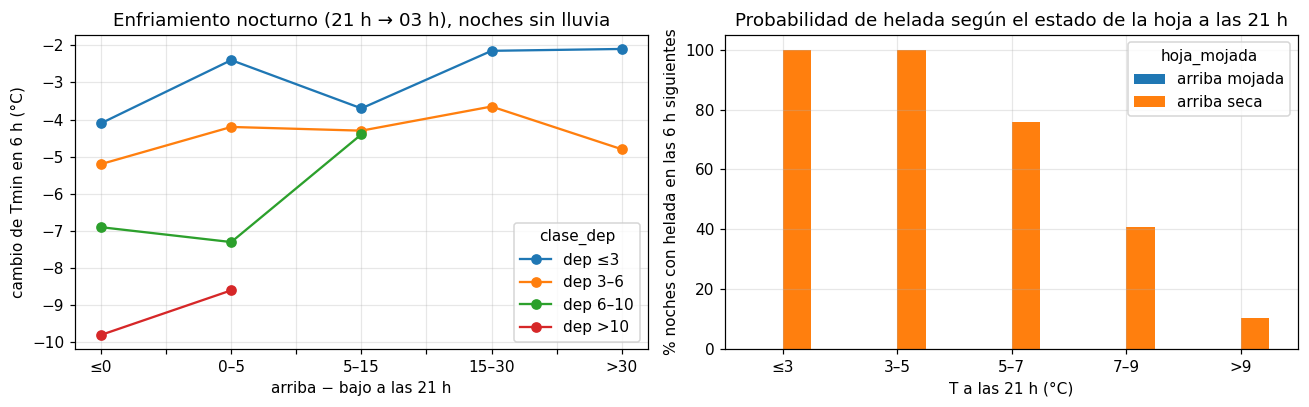

n por celda


clase_dep,dep ≤3,dep 3–6,dep 6–10,dep >10
clase_amb,,,,
≤0,2.0,175.0,356.0,64.0
0–5,9.0,72.0,84.0,2.0
5–15,7.0,11.0,2.0,NaN
15–30,10.0,4.0,NaN,NaN
>30,7.0,3.0,NaN,NaN


In [3]:
d21 = DF[(DF.index.hour == 21) & (DF['pp_24h'].fillna(0) == 0)].copy()
d21['enfr_6h'] = d21['y_T_6'] - d21['Tmin']
d21['clase_amb'] = pd.cut(d21['arriba_menos_bajo'], [-np.inf, 0, 5, 15, 30, np.inf],
                          labels=['≤0', '0–5', '5–15', '15–30', '>30'])
d21['clase_dep'] = pd.cut(d21['dep'], [0, 3, 6, 10, 40], labels=['dep ≤3', 'dep 3–6', 'dep 6–10', 'dep >10'])
tab = d21.pivot_table(index='clase_amb', columns='clase_dep', values='enfr_6h', aggfunc='median', observed=True)
cnt = d21.pivot_table(index='clase_amb', columns='clase_dep', values='enfr_6h', aggfunc='size', observed=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
tab.plot(marker='o', ax=axs[0]); axs[0].set_ylabel('cambio de Tmin en 6 h (°C)')
axs[0].set_xlabel('arriba − bajo a las 21 h'); axs[0].set_title('Enfriamiento nocturno (21 h → 03 h), noches sin lluvia')
# (b) frecuencia de helada en las próximas 6 h según el mojado de la hoja a las 21 h y la T
d21['clase_T'] = pd.cut(d21['T'], [-5, 3, 5, 7, 9, 30], labels=['≤3', '3–5', '5–7', '7–9', '>9'])
d21['hoja_mojada'] = np.where(d21['arriba_rel'] > UMB_MOJADO, 'arriba mojada', 'arriba seca')
fr = d21.assign(h=d21['y_T_alerta6'] <= 0).pivot_table(index='clase_T', columns='hoja_mojada', values='h',
                                                       aggfunc='mean', observed=True)
(fr * 100).plot(kind='bar', ax=axs[1], rot=0)
axs[1].set_xlabel('T a las 21 h (°C)'); axs[1].set_ylabel('% noches con helada en las 6 h siguientes')
axs[1].set_title('Probabilidad de helada según el estado de la hoja a las 21 h')
plt.tight_layout(); plt.show()
print('n por celda'); cnt

**(b)** Composición de las noches de helada (`Tmin ≤ 0 °C`) **alineadas en el inicio del mojado** de la cara superior. Si el sensor se adelanta al abrigo, la helada a 2 m debería llegar algunas horas después del mojado.

Noches de helada: 268  |  con hoja mojada antes o durante la helada: 85%


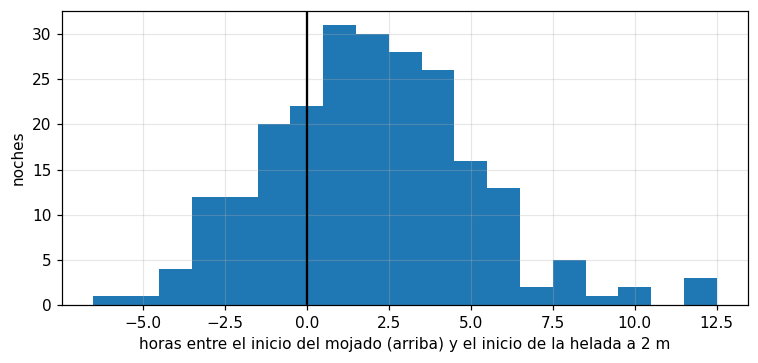

,count,mean,std,min,25%,50%,75%,max
estacion,,,,,,,,
J2 El Mantaro,229.0,2.0,3.2,-6.0,0.0,2.0,4.0,14.0


In [4]:
filas = []
for e in ESTACIONES:
    t = DF[DF.estacion == e]
    for noche, g in t.groupby('noche'):
        g = g.sort_index()
        if (g['Tmin'] <= 0).sum() == 0: continue
        moj = g.index[g['arriba_rel'] > UMB_MOJADO]
        hel = g.index[g['Tmin'] <= 0]
        filas.append({'estacion': e, 'noche': noche,
                      'h_inicio_mojado': moj[0] if len(moj) else pd.NaT, 'h_inicio_helada': hel[0]})
AD = pd.DataFrame(filas)
AD['adelanto_h'] = (AD['h_inicio_helada'] - AD['h_inicio_mojado']) / pd.Timedelta(hours=1)
print(f"Noches de helada: {len(AD)}  |  con hoja mojada antes o durante la helada: {AD['adelanto_h'].notna().mean():.0%}")
fig, ax = plt.subplots(figsize=(7, 3.4))
AD['adelanto_h'].clip(-6, 12).hist(bins=np.arange(-6.5, 13, 1), ax=ax)
ax.set_xlabel('horas entre el inicio del mojado (arriba) y el inicio de la helada a 2 m')
ax.set_ylabel('noches'); ax.axvline(0, color='k'); plt.tight_layout(); plt.show()
AD.groupby(AD.estacion.map(ETQ))['adelanto_h'].describe().round(1)

## 3. Validación cruzada dejando un año fuera

Para cada umbral (0 °C y 2 °C), cada plazo y cada variante entrenamos un clasificador. Para la variante sin hoja y la de hoja construida también entrenamos un regresor de la Tmin. Las predicciones de cada año salen de un modelo que **no vio ese año**.

In [5]:
def clf():
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_leaf_nodes=31,
                                          min_samples_leaf=40, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.15, random_state=SEED)
def reg():
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, max_leaf_nodes=31,
                                         min_samples_leaf=40, l2_regularization=1.0,
                                         early_stopping=True, validation_fraction=0.15, random_state=SEED)

ANIOS = sorted(DF['anio'].unique())
OOF = {}      # (umbral, plazo) -> DataFrame con y, inicio y probabilidades de cada variante
for nom_u, u in UMBRALES.items():
    for lead in [*LEADS, 'alerta6']:
        col = f'y_T_{lead}'
        sub = DF[DF[col].notna()]
        res = sub[['estacion', 'noche', 'anio', 'Tmin', col]].copy()
        res['y'] = sub[col] <= u
        res['inicio'] = sub['Tmin'] > u
        for a in ANIOS:
            tr, te = sub['anio'] != a, sub['anio'] == a
            for v, fs in VARIANTES.items():
                m = clf().fit(sub.loc[tr, fs], res.loc[tr, 'y'])
                res.loc[te, f'p_{v}'] = m.predict_proba(sub.loc[te, fs])[:, 1]
            if nom_u == 'meteorologica' and lead != 'alerta6':
                for v in ('sin hoja', 'hoja construida'):
                    r = reg().fit(sub.loc[tr, VARIANTES[v]], sub.loc[tr, col])
                    res.loc[te, f'T_{v}'] = r.predict(sub.loc[te, VARIANTES[v]])
        OOF[(nom_u, lead)] = res
    print('listo:', nom_u)

listo: meteorologica


listo: agronomica


### 3.1 Métricas

* **AUC** y **AP** (*average precision*, el área bajo la curva precisión-exhaustividad): miden cómo ordena los casos el modelo, sin depender de un umbral. AP es más informativa cuando el evento es raro.
* **BSS**: Brier skill score respecto de la climatología. 1 es perfecto y 0 equivale a no tener habilidad.
* **POD / FAR / CSI**: detección, falsas alarmas e índice de éxito, todos con una probabilidad de alerta fija de 0,5.

In [6]:
def csi(y, yh):
    a = (y & yh).sum(); b = (~y & yh).sum(); c = (y & ~yh).sum()
    return a / max(a + c, 1), b / max(a + b, 1), a / max(a + b + c, 1)

filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        t = res if casos == 'todos' else res[res['inicio']]
        y = t['y'].values
        if y.sum() < 10: continue
        bsc = brier_score_loss(y, np.full(len(y), y.mean()))
        for v in VARIANTES:
            p = t[f'p_{v}'].values
            pod, far, c = csi(y, p >= P_ALERTA)
            filas.append({'umbral': nom_u, 'plazo': lead, 'casos': casos, 'variante': v, 'n_eventos': int(y.sum()),
                          'AUC': roc_auc_score(y, p), 'AP': average_precision_score(y, p),
                          'BSS': 1 - brier_score_loss(y, p) / bsc, 'POD': pod, 'FAR': far, 'CSI': c})
MET = pd.DataFrame(filas)
MET.to_csv(OUT / 'el_mantaro_hoja_metricas.csv', index=False)
MET[MET.plazo.isin([1, 3, 6, 'alerta6'])].pivot_table(
    index=['umbral', 'casos', 'plazo'], columns='variante', values=['AP', 'BSS', 'CSI'], sort=False).round(3)

AP                                 BSS                                 CSI                           
variante                     sin hoja hoja cruda hoja construida sin hoja hoja cruda hoja construida sin hoja hoja cruda hoja construida
umbral        casos  plazo                                                                                                              
meteorologica todos  1          0.988      0.988           0.988    0.911      0.912           0.911    0.892      0.894           0.889
                     3          0.958      0.959           0.959    0.820      0.820           0.822    0.788      0.784           0.791
                     6          0.906      0.907           0.908    0.713      0.718           0.717    0.678      0.684           0.681
                     alerta6    0.948      0.950           0.953    0.772      0.777           0.786    0.752      0.755           0.764
              inicio 1          0.836      0.837           0.835    0.634      0.640           0.634    0.585      0.591           0.573
                     3          0.894      0.896           0.896    0.712      0.712           0.716    0.671      0.665           0.675
                     6          0.884      0.884           0.886    0.677      0.684           0.683    0.643      0.650           0.647
                     alerta6    0.869      0.875           0.881    0.646      0.653           0.667    0.622      0.625           0.640
agronomica    todos  1          0.988      0.988           0.988    0.900      0.899           0.900    0.881      0.880           0.881
                     3          0.939      0.939           0.939    0.769      0.769           0.766    0.746      0.748           0.741
                     6          0.882      0.884           0.887    0.666      0.668           0.666    0.653      0.657           0.650
                     alerta6    0.944      0.944           0.945    0.739      0.741           0.744    0.747      0.748           0.754
              inicio 1          0.780      0.780           0.781    0.587      0.582           0.588    0.532      0.541           0.551
                     3          0.820      0.814           0.817    0.611      0.609           0.605    0.579      0.584           0.575
                     6          0.833      0.836           0.841    0.605      0.607           0.605    0.595      0.599           0.590
                     alerta6    0.837      0.840           0.846    0.591      0.594           0.599    0.598      0.601           0.608

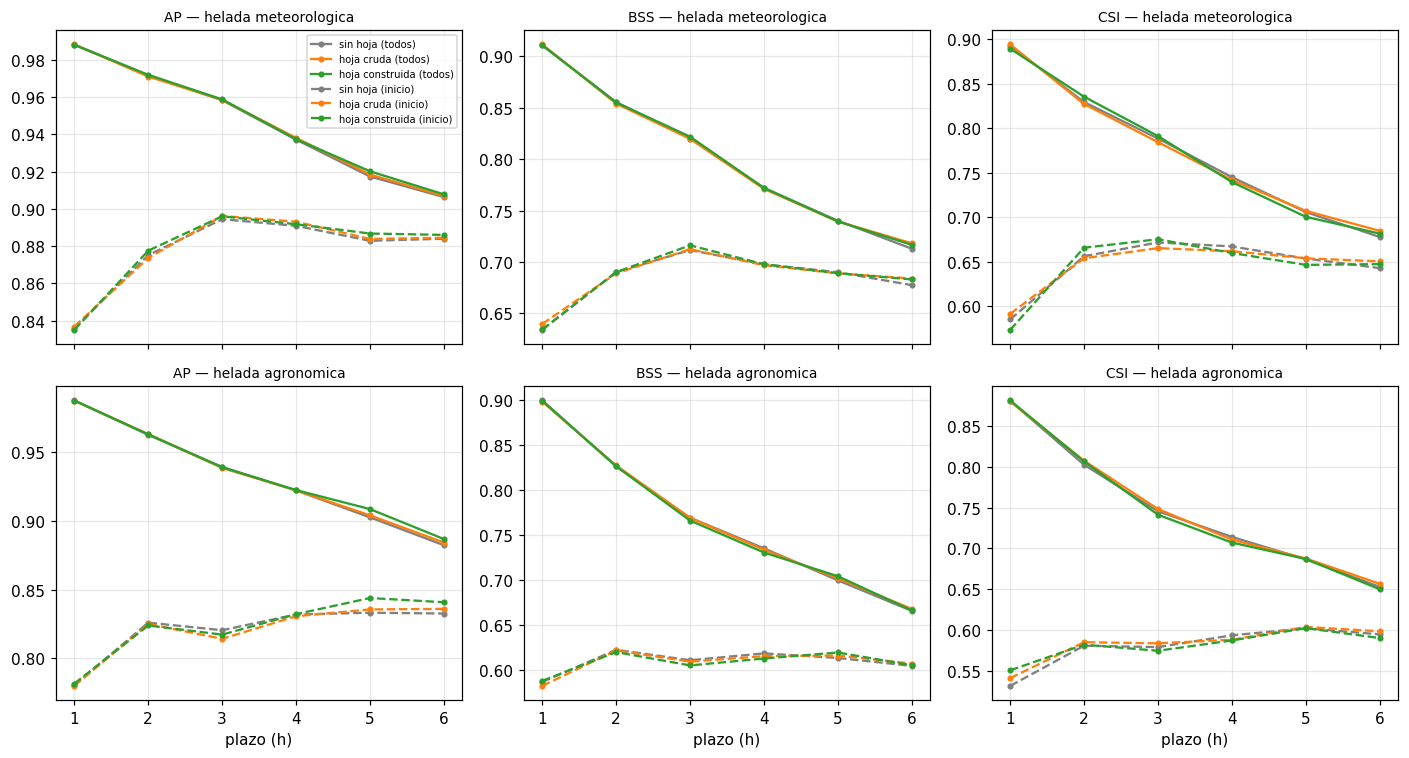

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for i, nom_u in enumerate(UMBRALES):
    for j, met in enumerate(['AP', 'BSS', 'CSI']):
        ax = axs[i, j]
        for casos, ls in [('todos', '-'), ('inicio', '--')]:
            g = MET[(MET.umbral == nom_u) & (MET.casos == casos) & (MET.plazo != 'alerta6')]
            for v, c in zip(VARIANTES, ['0.5', 'tab:orange', 'tab:green']):
                gv = g[g.variante == v]
                ax.plot(gv['plazo'].astype(int), gv[met], ls=ls, marker='o', ms=3, color=c,
                        label=f'{v} ({casos})')
        ax.set_title(f'{met} — helada {nom_u}', fontsize=9)
for ax in axs[-1]: ax.set_xlabel('plazo (h)')
axs[0, 0].legend(fontsize=6.5); plt.tight_layout(); plt.show()

### 3.2 ¿La mejora es real? Bootstrap por noche

Remuestreamos **noches completas** (estación × noche), porque las horas de una misma noche no son independientes. Calculamos la diferencia **hoja construida − sin hoja** en BSS y en CSI con un intervalo de confianza del 95 %. Si el intervalo no incluye el 0, la mejora es significativa.

In [8]:
def boot_diff(res, casos='todos', va='hoja construida', vb='sin hoja'):
    t = res if casos == 'todos' else res[res['inicio']]
    t = t.assign(clave=t['estacion'] + t['noche'].astype(str))
    y = t['y'].astype(float)
    g = pd.DataFrame({
        'n': 1.0, 'y': y,
        'se_a': (t[f'p_{va}'] - y) ** 2, 'se_b': (t[f'p_{vb}'] - y) ** 2,
        'a_a': (t['y'] & (t[f'p_{va}'] >= P_ALERTA)), 'b_a': (~t['y'] & (t[f'p_{va}'] >= P_ALERTA)),
        'c_a': (t['y'] & (t[f'p_{va}'] < P_ALERTA)),
        'a_b': (t['y'] & (t[f'p_{vb}'] >= P_ALERTA)), 'b_b': (~t['y'] & (t[f'p_{vb}'] >= P_ALERTA)),
        'c_b': (t['y'] & (t[f'p_{vb}'] < P_ALERTA)),
    }).astype(float).groupby(t['clave']).sum()
    W = rng.multinomial(len(g), np.ones(len(g)) / len(g), size=N_BOOT)    # pesos bootstrap por noche
    S = W @ g.values; S = pd.DataFrame(S, columns=g.columns)
    clim = S['y'] / S['n']
    bs_c = (S['y'] * (1 - clim) ** 2 + (S['n'] - S['y']) * clim ** 2) / S['n']
    dbss = (1 - S['se_a'] / S['n'] / bs_c) - (1 - S['se_b'] / S['n'] / bs_c)
    dcsi = S['a_a'] / (S['a_a'] + S['b_a'] + S['c_a']) - S['a_b'] / (S['a_b'] + S['b_b'] + S['c_b'])
    return dbss, dcsi

filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        if res[res['inicio'] if casos == 'inicio' else slice(None)]['y'].sum() < 10: continue
        dbss, dcsi = boot_diff(res, casos)
        filas.append({'umbral': nom_u, 'plazo': lead, 'casos': casos,
                      'ΔBSS': dbss.median(), 'ΔBSS IC95': f'[{dbss.quantile(.025):+.3f}, {dbss.quantile(.975):+.3f}]',
                      'ΔCSI': dcsi.median(), 'ΔCSI IC95': f'[{dcsi.quantile(.025):+.3f}, {dcsi.quantile(.975):+.3f}]',
                      'significativo_BSS': dbss.quantile(.025) > 0, 'significativo_CSI': dcsi.quantile(.025) > 0})
BOOT = pd.DataFrame(filas)
BOOT.to_csv(OUT / 'el_mantaro_hoja_bootstrap.csv', index=False)
BOOT.round(3)

,umbral,plazo,casos,ΔBSS,ΔBSS IC95,ΔCSI,ΔCSI IC95,significativo_BSS,significativo_CSI
0,meteorologica,1,todos,0.000,"[-0.003, +0.003]",-0.003,"[-0.010, +0.004]",False,False
1,meteorologica,1,inicio,0.001,"[-0.014, +0.016]",-0.012,"[-0.038, +0.017]",False,False
2,meteorologica,2,todos,-0.000,"[-0.004, +0.003]",0.006,"[-0.001, +0.014]",False,False
3,meteorologica,2,inicio,0.000,"[-0.008, +0.009]",0.010,"[-0.005, +0.027]",False,False
4,meteorologica,3,todos,0.002,"[-0.003, +0.006]",0.003,"[-0.008, +0.014]",False,False
5,meteorologica,3,inicio,0.005,"[-0.003, +0.012]",0.003,"[-0.013, +0.020]",False,False
6,meteorologica,4,todos,-0.000,"[-0.005, +0.005]",-0.006,"[-0.015, +0.004]",False,False
7,meteorologica,4,inicio,0.000,"[-0.007, +0.007]",-0.007,"[-0.021, +0.006]",False,False
8,meteorologica,5,todos,-0.001,"[-0.006, +0.006]",-0.005,"[-0.015, +0.006]",False,False
9,meteorologica,5,inicio,-0.001,"[-0.008, +0.007]",-0.008,"[-0.021, +0.006]",False,False


### 3.3 Temperatura mínima pronosticada (umbral de 0 °C, regresor)

In [9]:
filas = []
for lead in LEADS:
    res = OOF[('meteorologica', lead)]
    y = res[f'y_T_{lead}']
    for casos, m in [('todos', y.notna()), ('noches frías (Tmin obs ≤ 3 °C)', y <= 3)]:
        filas.append({'plazo': lead, 'casos': casos,
                      'MAE persistencia': mean_absolute_error(y[m], res.loc[m, 'Tmin']),
                      'MAE sin hoja': mean_absolute_error(y[m], res.loc[m, 'T_sin hoja']),
                      'MAE hoja construida': mean_absolute_error(y[m], res.loc[m, 'T_hoja construida']),
                      'sesgo sin hoja': (res.loc[m, 'T_sin hoja'] - y[m]).mean(),
                      'sesgo hoja construida': (res.loc[m, 'T_hoja construida'] - y[m]).mean()})
pd.DataFrame(filas).round(2)

,plazo,casos,MAE persistencia,MAE sin hoja,MAE hoja construida,sesgo sin hoja,sesgo hoja construida
0,1,todos,1.09,0.60,0.60,-0.01,-0.01
1,1,noches frías (Tmin obs ≤ 3 °C),0.82,0.36,0.36,0.15,0.16
2,2,todos,2.17,0.89,0.89,-0.02,-0.01
3,2,noches frías (Tmin obs ≤ 3 °C),1.60,0.59,0.59,0.35,0.35
4,3,todos,3.26,1.04,1.05,-0.02,-0.02
5,3,noches frías (Tmin obs ≤ 3 °C),2.52,0.83,0.83,0.59,0.60
6,4,todos,4.29,1.14,1.14,-0.02,-0.03
7,4,noches frías (Tmin obs ≤ 3 °C),3.61,1.00,0.99,0.75,0.74
8,5,todos,5.28,1.21,1.21,-0.01,-0.02
9,5,noches frías (Tmin obs ≤ 3 °C),4.84,1.15,1.13,0.89,0.88


### 3.4 Resultados por año (plazo de 3 h, umbral de 0 °C)

In [10]:
res = OOF[('meteorologica', 3)]
filas = []
for e, t in res.groupby('anio'):
    y = t['y'].values
    if y.sum() < 5: continue
    for v in VARIANTES:
        p = t[f'p_{v}'].values
        pod, far, c = csi(y, p >= P_ALERTA)
        filas.append({'anio': e, 'variante': v, 'eventos': int(y.sum()),
                      'AP': average_precision_score(y, p), 'POD': pod, 'FAR': far, 'CSI': c})
pd.DataFrame(filas).pivot_table(index=['anio', 'eventos'], columns='variante', values=['AP', 'CSI']).round(3)

AP                                 CSI                    
variante     hoja construida hoja cruda sin hoja hoja construida hoja cruda sin hoja
anio eventos                                                                        
2022 368               0.945      0.946    0.945           0.744      0.729    0.744
2023 392               0.974      0.973    0.972           0.835      0.831    0.843
2024 255               0.950      0.947    0.947           0.762      0.755    0.752
2025 279               0.974      0.974    0.973           0.846      0.834    0.822
2026 44                0.935      0.940    0.941           0.660      0.725    0.708

## 4. ¿Qué variables de hoja usa el modelo?

Importancia por permutación (caída de AP) del modelo con hoja construida, a 3 h y con el umbral de 2 °C, entrenado con 2022–2024 y evaluado en 2025–2026.

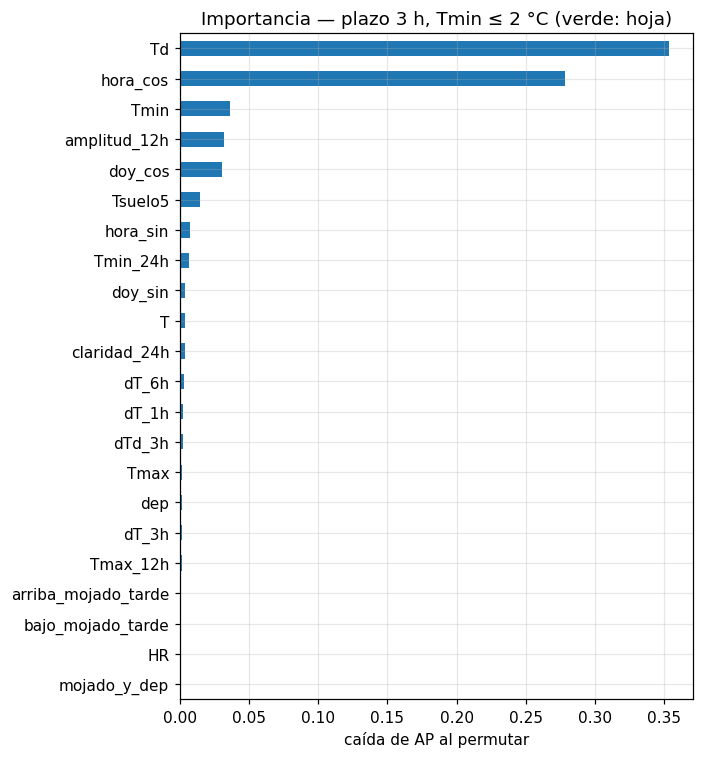

In [11]:
col = 'y_T_3'; sub = DF[DF[col].notna()]
tr, te = sub['anio'] <= 2024, sub['anio'] >= 2025
m = clf().fit(sub.loc[tr, VARIANTES['hoja construida']], sub.loc[tr, col] <= 2)
pi = permutation_importance(m, sub.loc[te, VARIANTES['hoja construida']], sub.loc[te, col] <= 2,
                            scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=VARIANTES['hoja construida']).sort_values().tail(22)
fig, ax = plt.subplots(figsize=(6.5, 7))
imp.plot.barh(ax=ax, color=['tab:green' if f in F_HOJA else 'tab:blue' for f in imp.index])
ax.set_xlabel('caída de AP al permutar'); ax.set_title('Importancia — plazo 3 h, Tmin ≤ 2 °C (verde: hoja)')
plt.tight_layout(); plt.show()

## 5. Ejemplos de noches (predicciones fuera de muestra)

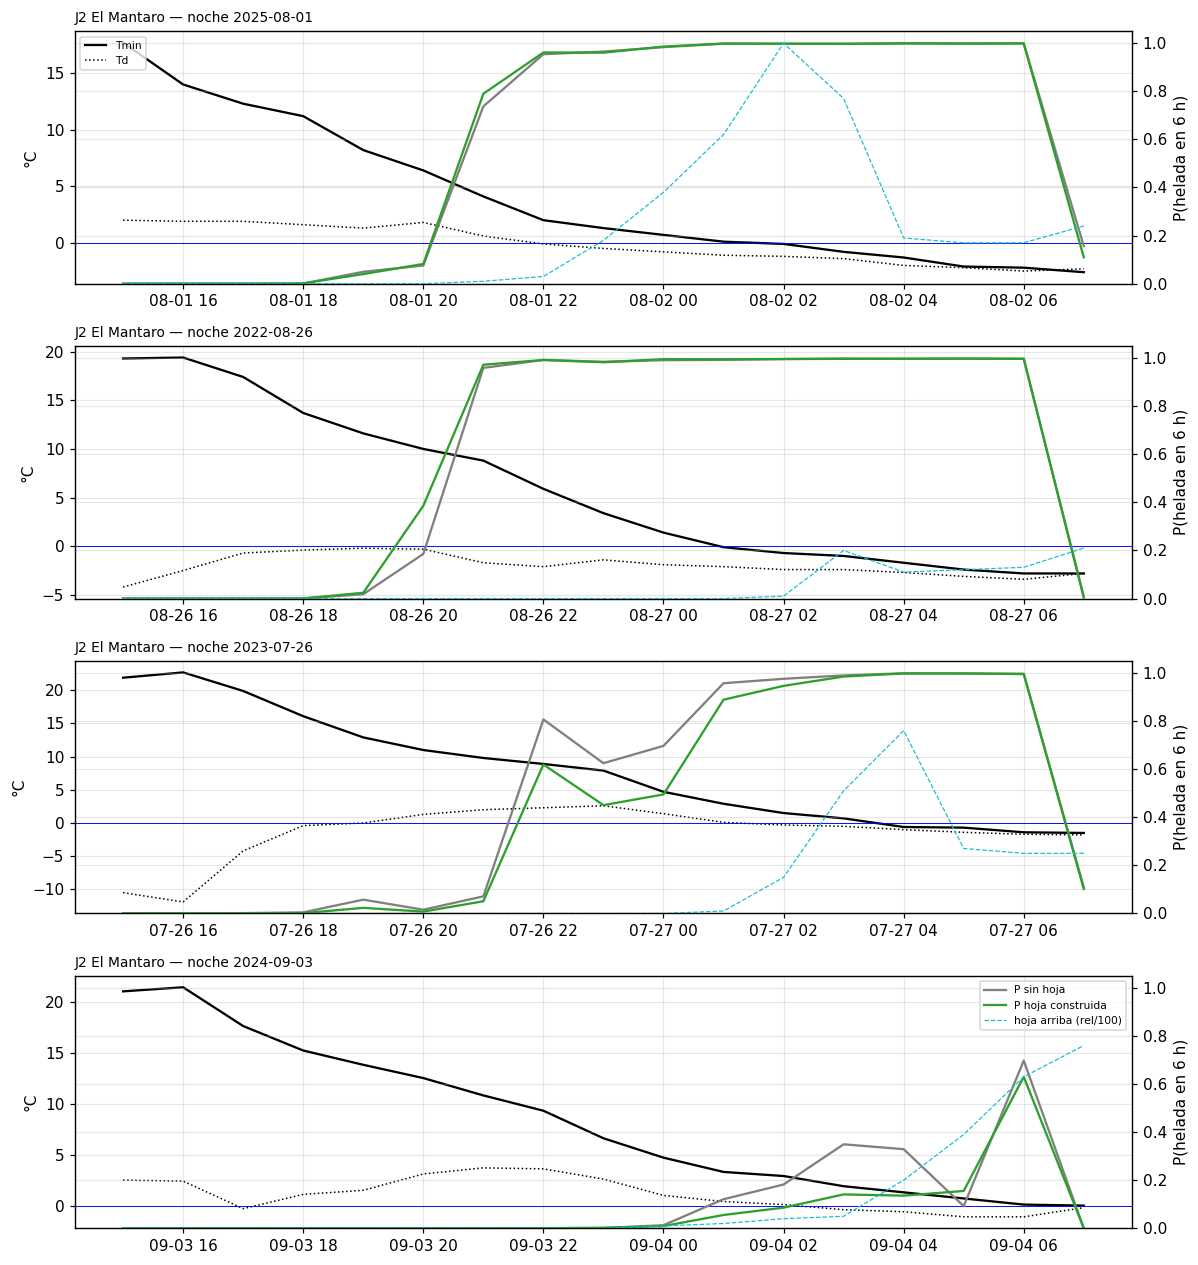

In [12]:
res6 = OOF[('meteorologica', 'alerta6')]
noches_h = (res6[res6['y']].groupby(['estacion', 'noche']).size()
            .reset_index().sample(4, random_state=3)[['estacion', 'noche']].values)
fig, axs = plt.subplots(len(noches_h), 1, figsize=(11, 2.9 * len(noches_h)), squeeze=False)
for ax, (e, noche) in zip(axs[:, 0], noches_h):
    ini, fin = noche + pd.Timedelta(hours=15), noche + pd.Timedelta(hours=32)
    o = DF[DF.estacion == e].loc[ini:fin]
    ax.plot(o.index, o['Tmin'], 'k-', lw=1.5, label='Tmin'); ax.plot(o.index, o['Td'], 'k:', lw=1, label='Td')
    ax.axhline(0, color='b', lw=.6); ax.set_ylabel('°C')
    ax2 = ax.twinx()
    r = res6[res6.estacion == e].loc[ini:fin]
    ax2.plot(r.index, r['p_sin hoja'], color='0.5', label='P sin hoja')
    ax2.plot(r.index, r['p_hoja construida'], color='tab:green', label='P hoja construida')
    ax2.plot(o.index, o['arriba_rel'].clip(0, 100) / 100, color='tab:cyan', lw=.8, ls='--', label='hoja arriba (rel/100)')
    ax2.set_ylim(0, 1.05); ax2.set_ylabel('P(helada en 6 h)')
    ax.set_title(f'{ETQ[e]} — noche {pd.Timestamp(noche):%Y-%m-%d}', fontsize=9, loc='left')
axs[0, 0].legend(fontsize=7, loc='upper left'); ax2.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()

## 6. Modelo final de El Mantaro

Entrenamos con **todos los años** la variante con hoja construida, que el modelo puede usar en las estaciones que tienen sensor de hoja, y también la variante sin hoja como respaldo para cuando el sensor falle. Lo guardamos todo en `resultados/modelos/el_mantaro_heladas_hoja.joblib`.

In [13]:
FINAL = {'umbrales': UMBRALES, 'leads': LEADS, 'p_alerta': P_ALERTA,
         'feats': {v: VARIANTES[v] for v in ('sin hoja', 'hoja construida')}, 'clf': {}, 'reg': {}}
for nom_u, u in UMBRALES.items():
    for lead in [*LEADS, 'alerta6']:
        col = f'y_T_{lead}'; sub = DF[DF[col].notna()]
        for v in ('sin hoja', 'hoja construida'):
            FINAL['clf'][(nom_u, lead, v)] = clf().fit(sub[VARIANTES[v]], sub[col] <= u)
for lead in LEADS:
    col = f'y_T_{lead}'; sub = DF[DF[col].notna()]
    for v in ('sin hoja', 'hoja construida'):
        FINAL['reg'][(lead, v)] = reg().fit(sub[VARIANTES[v]], sub[col])
joblib.dump(FINAL, OUT / 'modelos' / 'el_mantaro_heladas_hoja.joblib')

def pronosticar(d_horario, est, t, modelo=FINAL):
    # d_horario: CSV horario (data/processed/horario) de la estación, con al menos 60 días previos a t
    #   (claridad_24h usa una ventana de 60 días; la línea base de la hoja, 30). Lo más simple: pasar el CSV completo.
    d = d_horario.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    d = d.asfreq('h')
    X = var_meteo(d, est).join(var_hoja(d))
    t = pd.Timestamp(t)
    hoja_ok = pd.notna(d.loc[t, 'arriba']) and pd.notna(d.loc[t, 'bajo'])
    v = 'hoja construida' if hoja_ok else 'sin hoja'
    x = X.loc[[t], modelo['feats'][v]]
    filas = []
    for lead in [*modelo['leads'], 'alerta6']:
        f = {'plazo': lead, 'hora_objetivo': t + pd.Timedelta(hours=6 if lead == 'alerta6' else lead), 'variante': v}
        for nom_u in modelo['umbrales']:
            f[f'P_{nom_u}'] = round(float(modelo['clf'][(nom_u, lead, v)].predict_proba(x)[0, 1]), 3)
        if lead != 'alerta6':
            f['Tmin_pron'] = round(float(modelo['reg'][(lead, v)].predict(x)[0]), 1)
        filas.append(f)
    out = pd.DataFrame(filas)
    out['alerta_0C'] = out['P_meteorologica'] >= modelo['p_alerta']
    out['alerta_2C'] = out['P_agronomica'] >= modelo['p_alerta']
    return out

e = 'j2_el_mantaro'
raw = pd.read_csv(DATA / 'horario' / f'{e}.csv', parse_dates=['fecha'])
t_ej = res6[(res6.estacion == e) & res6['y'] & (res6.index.hour == 21)].index[-1]
print(ETQ[e], 'emisión', t_ej)
pronosticar(raw, e, t_ej)

J2 El Mantaro emisión 2026-09-30 21:00:00


,plazo,hora_objetivo,variante,P_meteorologica,P_agronomica,Tmin_pron,alerta_0C,alerta_2C
0,1,2026-09-30 22:00:00,hoja construida,0.000,0.002,6.5,False,False
1,2,2026-09-30 23:00:00,hoja construida,0.002,0.003,4.7,False,False
2,3,2026-10-01 00:00:00,hoja construida,0.006,0.420,3.0,False,False
3,4,2026-10-01 01:00:00,hoja construida,0.038,0.843,1.8,False,True
4,5,2026-10-01 02:00:00,hoja construida,0.029,0.960,0.7,False,True
5,6,2026-10-01 03:00:00,hoja construida,0.843,0.963,-0.6,True,True
6,alerta6,2026-10-01 03:00:00,hoja construida,0.892,0.992,NaN,True,True


## 7. Conclusiones

Las conclusiones numéricas están en las tablas de las secciones 3.1–3.4 y en `resultados/el_mantaro_hoja_*.csv`. Para leerlas:

* Si el **ΔBSS / ΔCSI** de la sección 3.2 es positivo y su intervalo no cruza el 0, la humedad de hoja **aporta información** que la temperatura, la humedad y el viento no contienen.
* El efecto debería verse sobre todo en el **umbral agronómico (2 °C)** y en los **casos de inicio**, porque ahí la hoja, que mide en la superficie, se adelanta al abrigo.
* Un modelo así depende de que el sensor de hoja esté **sano**. La línea base calculada con datos pasados corrige la deriva lenta, pero un sensor sucio o roto hay que detectarlo y, en ese caso, usar el modelo de respaldo **sin hoja** (`pronosticar` cambia de variante automáticamente si falta el dato).